# Model 3: Tuning a MobileNetV2 flower classifier with Hyperband

Frozen MobileNetV2 features, a small classifier on top, and Hyperband to search the settings.

In [1]:
from pathlib import Path

import keras
import keras_tuner as kt
import matplotlib.pyplot as plt
import pandas as pd
from keras.applications import mobilenet_v2

keras.utils.set_random_seed(42)
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32
DATA = Path("data")


def load_images(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        DATA / split, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, label_mode="int", shuffle=shuffle, seed=42
    )


train_ds = load_images("train", shuffle=True)
valid_ds = load_images("validation", shuffle=False)
test_ds = load_images("test", shuffle=False)
class_names = train_ds.class_names
class_names

Found 300 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 30 files belonging to 3 classes.


['rose', 'sunflower', 'tulip']

## Base model and helpers

The base is frozen. Raw 0-255 photos go into the model, and a `Rescaling` layer maps them to -1...1 as MobileNetV2 expects.

In [2]:
base = mobilenet_v2.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)
base.trainable = False


def plot_curves(logs, title):
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    logs[["loss", "val_loss"]].plot(ax=ax_loss, xlabel="Epoch", title=f"{title}: loss")
    logs[["accuracy", "val_accuracy"]].plot(ax=ax_acc, xlabel="Epoch", title=f"{title}: accuracy")
    plt.show()

## The search space

Hyperband tunes whether to augment (and how strongly), the dropout rate, the L2 penalty and the learning rate.

In [5]:
def build_model(hp):
    layers = [keras.Input(shape=IMAGE_SIZE + (3,))]
    layers += [
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),
        base,
        keras.layers.Dropout(hp.Float("dropout", 0.0, 0.5, step=0.1)),
        keras.layers.Dense(
            len(class_names),
            activation="softmax",
            kernel_regularizer=keras.regularizers.L2(hp.Choice("l2", [0.0, 1e-4, 1e-3, 1e-2])),
        ),
    ]
    model = keras.Sequential(layers)
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(hp.Choice("learning_rate", [1e-2, 1e-3, 1e-4])),
        metrics=["accuracy"],
    )
    return model

## Run Hyperband

It trains many settings for a few epochs and keeps training only the best third at each round, up to 30 epochs.

In [6]:
tuner = kt.Hyperband(
    build_model,
    objective="val_accuracy",
    max_epochs=30,
    factor=3,
    seed=42,
    directory="tuner",
    project_name="hyperband_flowers",
    overwrite=True,
)

stop_early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5)
tuner.search(train_ds, validation_data=valid_ds, callbacks=[stop_early], verbose=0)

best_hp = tuner.get_best_hyperparameters(1)[0]
best_hp.values

{'dropout': 0.30000000000000004,
 'l2': 0.0,
 'learning_rate': 0.001,
 'tuner/epochs': 10,
 'tuner/initial_epoch': 4,
 'tuner/bracket': 3,
 'tuner/round': 2,
 'tuner/trial_id': '0045'}

## Train the best settings and evaluate

The best settings are rebuilt from scratch and trained for 30 epochs so we can see the learning curves.

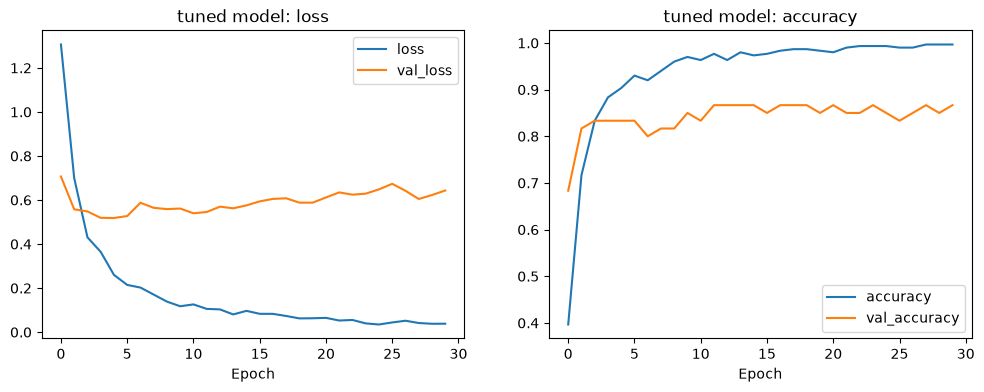

Validation accuracy: 0.867


In [7]:
keras.utils.set_random_seed(42)
tuned_model = tuner.hypermodel.build(best_hp)
history = tuned_model.fit(train_ds, validation_data=valid_ds, epochs=30, verbose=0)

plot_curves(pd.DataFrame(history.history, index=history.epoch), "tuned model")
val_acc = tuned_model.evaluate(valid_ds, verbose=0)[1]
print(f"Validation accuracy: {val_acc:.3f}")

## Test set

The test photos were not used for tuning, so this is the fair number to compare with Models 1 and 2.

Test accuracy: 0.933


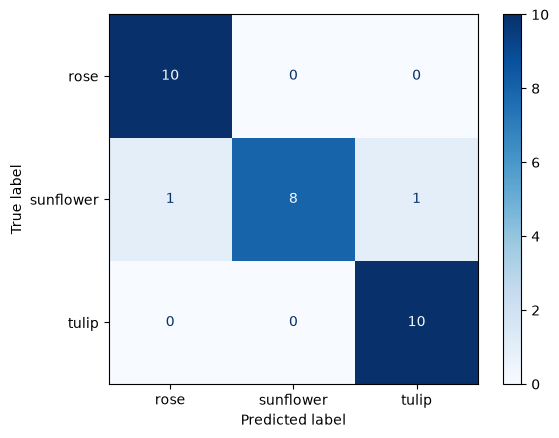

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = tuned_model.predict(test_ds, verbose=0).argmax(axis=1)
print(f"Test accuracy: {(y_true == y_pred).mean():.3f}")
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names, cmap="Blues")
plt.show()

In [9]:
Path("models").mkdir(exist_ok=True)
tuned_model.save("models/tuned_model.keras")

2 of 30 test photos misclassified


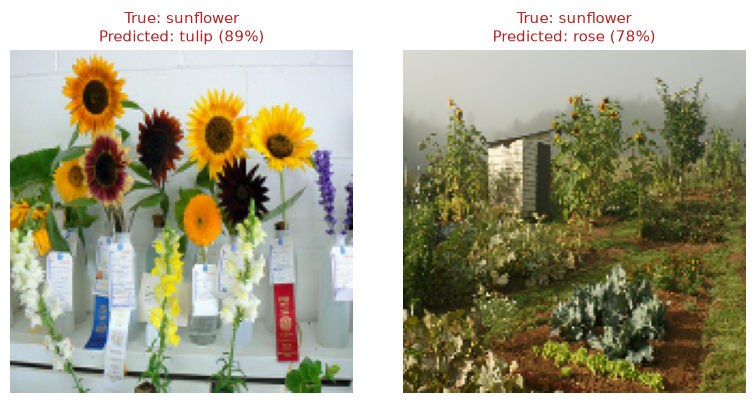

In [10]:
import math

# Images in the same order as y_true / y_pred
test_images = np.concatenate([x.numpy() for x, _ in test_ds]).astype("uint8")
probs = tuned_model.predict(test_ds, verbose=0)

wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} of {len(y_true)} test photos misclassified")

cols = min(4, max(len(wrong), 1))
rows = math.ceil(len(wrong) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong):
    ax.imshow(test_images[i])
    ax.set_title(
        f"True: {class_names[y_true[i]]}\nPredicted: {class_names[y_pred[i]]} ({probs[i].max():.0%})",
        color="firebrick",
        fontsize=11,
    )
plt.tight_layout()
plt.show()